# Capstone Project: Product Return Prediction for an E-Commerce Company

## Task 1 - Understand the business problem

Returns are one of the largest operational costs for an e-commerce marketplace. Every
returned order incurs reverse logistics, inspection, repackaging and refund costs. Our
task is to build a **binary classification** model that predicts, **before an order ships**,
whether it will be **returned**, so the business can act early (improve product info,
recommend prepaid payment, add quality checks, optimise logistics).

**Target variable:** `returned`  (`0` = not returned, `1` = returned)

This notebook follows the 12 tasks in the problem statement and also applies:
**outlier detection & removal**, **`class_weight='balanced'`** for class imbalance,


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
import joblib

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

In [2]:
#reading the data set
import pandas as pd
df= pd.read_csv("dataset/returns_dataset.csv")
print(df.shape)
df.head()

(12000, 26)


,order_id,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,ORD100000,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,0.172,0.173,0.219,0.116,4.1,0.128,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,ORD100001,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,0.168,0.125,0.155,0.031,4.2,0.171,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,ORD100002,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,0.045,0.125,0.103,0.057,4.1,0.186,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0
3,ORD100003,Electronics,Laptops,Brand_30,1301.55,25.3,3.8,57.0,0,1,0.066,0.119,0.085,0.064,3.9,0.133,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,0
4,ORD100004,Electronics,Laptops,Brand_15,1402.90,30.6,3.0,71.0,0,1,0.183,0.075,0.177,0.076,4.6,0.172,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,0


In [3]:
#cheacking for return items and counting them
df["returned"].value_counts()

returned
0    8355
1    3645
Name: count, dtype: int64

In [4]:
import matplotlib.pyplot as plt

returned
0    8355
1    3645
Name: count, dtype: int64
returned
0    69.62
1    30.38
Name: proportion, dtype: float64


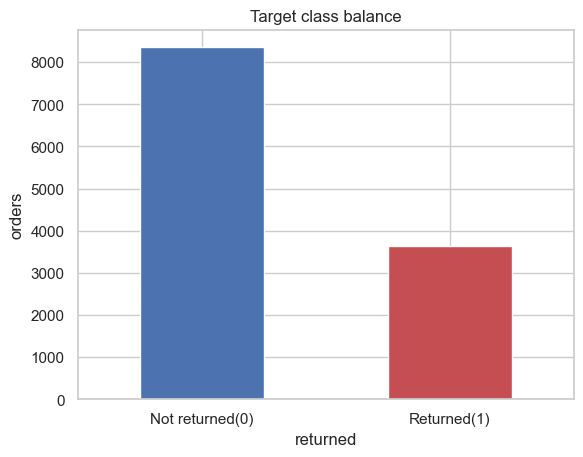

In [5]:
#Target Class Balance Analysis using barchart
counts= df["returned"].value_counts()   #Total 0 and 1 
print(counts)

print((df["returned"].value_counts(normalize=True) * 100).round(2))    #this converts into percentage for easy to compare and understand

ax= counts.plot(kind= "bar", color= ["#4c72b0", "#c44e52"])           #counts.plot is pandas way to plot the data kind= "bar" and store it in ax for later customizes
ax.set_xticklabels(["Not returned(0)", "Returned(1)"], rotation= 0)   #lables for bar charts (xlabel)
ax.set_title("Target class balance")                                  #title
ax.set_ylabel("orders")                                               #ylabel
plt.show()                                                            #show plot

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   order_id                  12000 non-null  object 
 1   product_category          12000 non-null  object 
 2   sub_category              12000 non-null  object 
 3   brand                     12000 non-null  object 
 4   product_price             12000 non-null  float64
 5   discount_percent          12000 non-null  float64
 6   product_rating            11760 non-null  float64
 7   review_count              11880 non-null  float64
 8   fragile_item              12000 non-null  int64  
 9   warranty_available        12000 non-null  int64  
 10  product_return_rate       12000 non-null  float64
 11  category_return_rate      12000 non-null  float64
 12  brand_return_rate         12000 non-null  float64
 13  defect_rate               12000 non-null  float64
 14  seller

In [7]:
#for numeric summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
product_price,12000.0,964.063342,1678.771489,19.510,328.235,597.470,1105.395,64878.670
discount_percent,12000.0,33.567167,19.378304,0.000,16.800,33.500,50.400,67.000
product_rating,11760.0,3.886505,0.635664,1.600,3.500,3.900,4.300,5.000
review_count,11880.0,69.437205,18.446294,24.000,54.000,69.000,85.000,116.000
fragile_item,12000.0,0.197083,0.397812,0.000,0.000,0.000,0.000,1.000
warranty_available,12000.0,0.446500,0.497150,0.000,0.000,0.000,1.000,1.000
product_return_rate,12000.0,0.132522,0.069787,0.001,0.082,0.134,0.183,0.367
category_return_rate,12000.0,0.120377,0.049559,0.001,0.087,0.120,0.154,0.354
brand_return_rate,12000.0,0.131886,0.059397,0.010,0.090,0.135,0.176,0.322
defect_rate,12000.0,0.060629,0.042730,0.000,0.029,0.051,0.082,0.370


<Axes: >

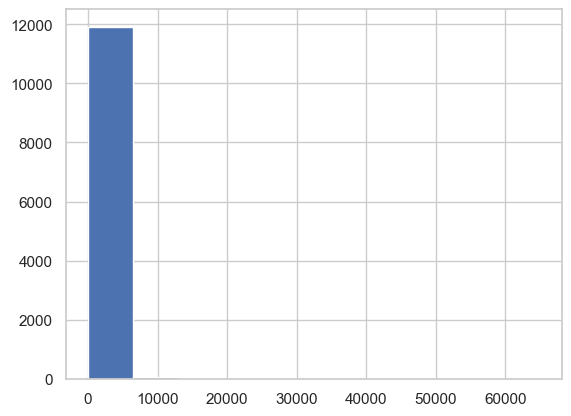

In [8]:
df.product_price.hist()

In [9]:
#looking for null values
df.isnull().sum()

order_id                      0
product_category              0
sub_category                  0
brand                         0
product_price                 0
discount_percent              0
product_rating              240
review_count                120
fragile_item                  0
warranty_available            0
product_return_rate           0
category_return_rate          0
brand_return_rate             0
defect_rate                   0
seller_rating               180
seller_return_rate            0
fulfillment_type              0
payment_method                0
quantity                      0
shipping_distance_km        120
delayed_delivery              0
wishlist_before_purchase      0
product_page_views            0
customer_support_calls        0
chat_interactions             0
returned                      0
dtype: int64

In [10]:
#categorical columns
categorical_columns= ["product_category", "sub_category", "brand", "fulfillment_type", "payment_method"]

for col in categorical_columns:
    print(df[col].value_counts())
    print()


product_category
Fashion        3413
Electronics    2601
Home           1816
Beauty         1453
Sports         1202
Books           910
Toys            605
Name: count, dtype: int64

sub_category
Mobiles           904
Audio             862
Laptops           835
Women             706
Accessories       684
Footwear          681
Men               673
Kids              669
Kitchen           614
Furniture         614
Decor             588
Haircare          505
Skincare          485
Makeup            463
Team Sports       439
Fitness           389
Outdoor           374
Non-Fiction       335
Fiction           288
Academic          287
Outdoor Play      220
Educational       195
Action Figures    190
Name: count, dtype: int64

brand
Brand_26    442
Brand_21    431
Brand_24    427
Brand_1     425
Brand_15    420
Brand_5     418
Brand_22    418
Brand_11    413
Brand_9     411
Brand_30    410
Brand_7     408
Brand_2     407
Brand_19    406
Brand_14    405
Brand_25    403
Brand_4     400
Brand_29

In [11]:
df["product_category"].value_counts()

product_category
Fashion        3413
Electronics    2601
Home           1816
Beauty         1453
Sports         1202
Books           910
Toys            605
Name: count, dtype: int64

##### we are going to do analysis on payment_method like  on payment mode to see how many products are returned in every payment mode

In [12]:
df.columns

Index(['order_id', 'product_category', 'sub_category', 'brand',
       'product_price', 'discount_percent', 'product_rating', 'review_count',
       'fragile_item', 'warranty_available', 'product_return_rate',
       'category_return_rate', 'brand_return_rate', 'defect_rate',
       'seller_rating', 'seller_return_rate', 'fulfillment_type',
       'payment_method', 'quantity', 'shipping_distance_km',
       'delayed_delivery', 'wishlist_before_purchase', 'product_page_views',
       'customer_support_calls', 'chat_interactions', 'returned'],
      dtype='object')

In [13]:
df.groupby(col)["returned"].mean().sort_values(ascending= False)

payment_method
COD            0.505236
Wallet         0.235993
Debit Card     0.228943
Credit Card    0.198724
UPI            0.156847
Name: returned, dtype: float64

##### 
fig = the entire figure (the canvas).

axes = the individual plotting areas.

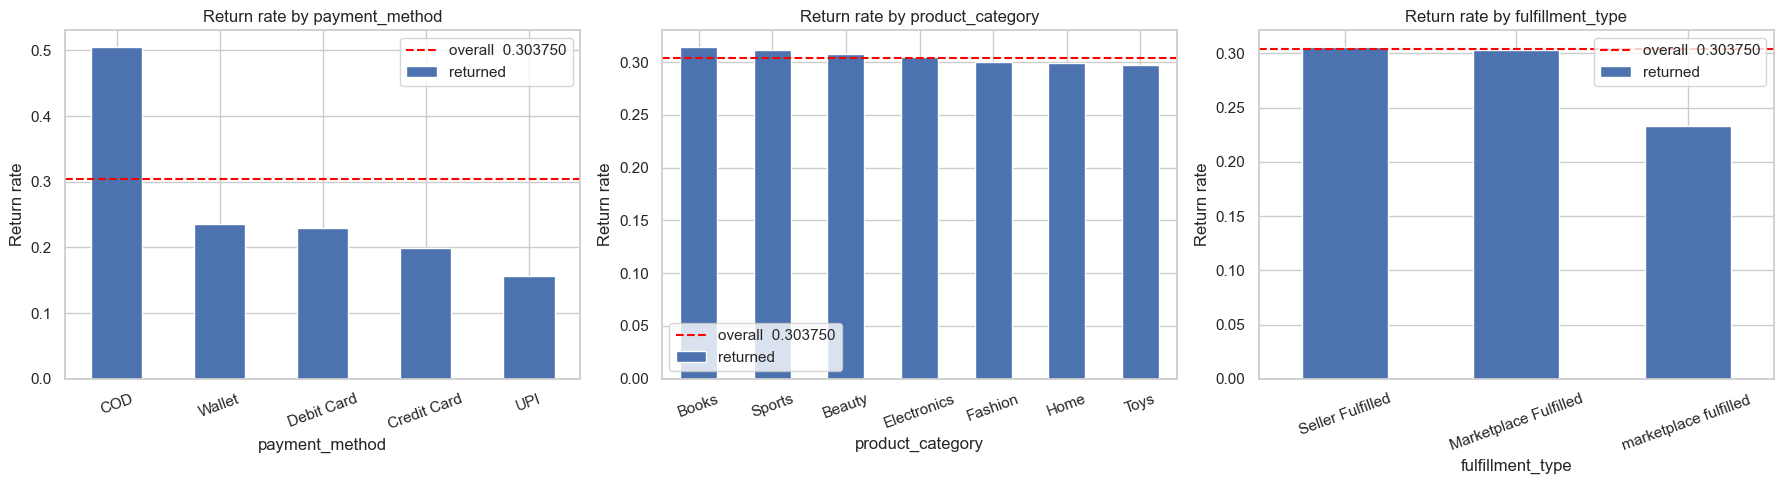

In [14]:
fig, axes= plt.subplots(1, 3, figsize= (18, 5))    #Create three plots in one figure
#plt.subplots(rows, columns)

overall= df["returned"].mean()

for ax, col in zip(axes, ["payment_method", "product_category", "fulfillment_type"]):
    rate= df.groupby(col)["returned"].mean().sort_values(ascending= False)     #calculating and grouping "returned" column in decending order with respect to col
    
    rate.plot(kind= "bar", ax= ax, color= "#4c72b0") #ploting the data into bar
    
    ax.axhline(overall, color= "Red", ls= "--", label= f"overall {overall: 2f}")  #drawing horizontal line here, based on our mean() 
    
    ax.set_title(f"Return rate by {col}")   # with the help of {} it changes every fig name
    ax.set_ylabel("Return rate")
    ax.tick_params(axis= "x", rotation= 20)
    ax.legend()

plt.tight_layout()
plt.show()
     
    

In [15]:
df["returned"]

0        1
1        0
2        0
3        0
4        0
        ..
11995    1
11996    0
11997    0
11998    0
11999    1
Name: returned, Length: 12000, dtype: int64

In [16]:
df.columns

Index(['order_id', 'product_category', 'sub_category', 'brand',
       'product_price', 'discount_percent', 'product_rating', 'review_count',
       'fragile_item', 'warranty_available', 'product_return_rate',
       'category_return_rate', 'brand_return_rate', 'defect_rate',
       'seller_rating', 'seller_return_rate', 'fulfillment_type',
       'payment_method', 'quantity', 'shipping_distance_km',
       'delayed_delivery', 'wishlist_before_purchase', 'product_page_views',
       'customer_support_calls', 'chat_interactions', 'returned'],
      dtype='object')

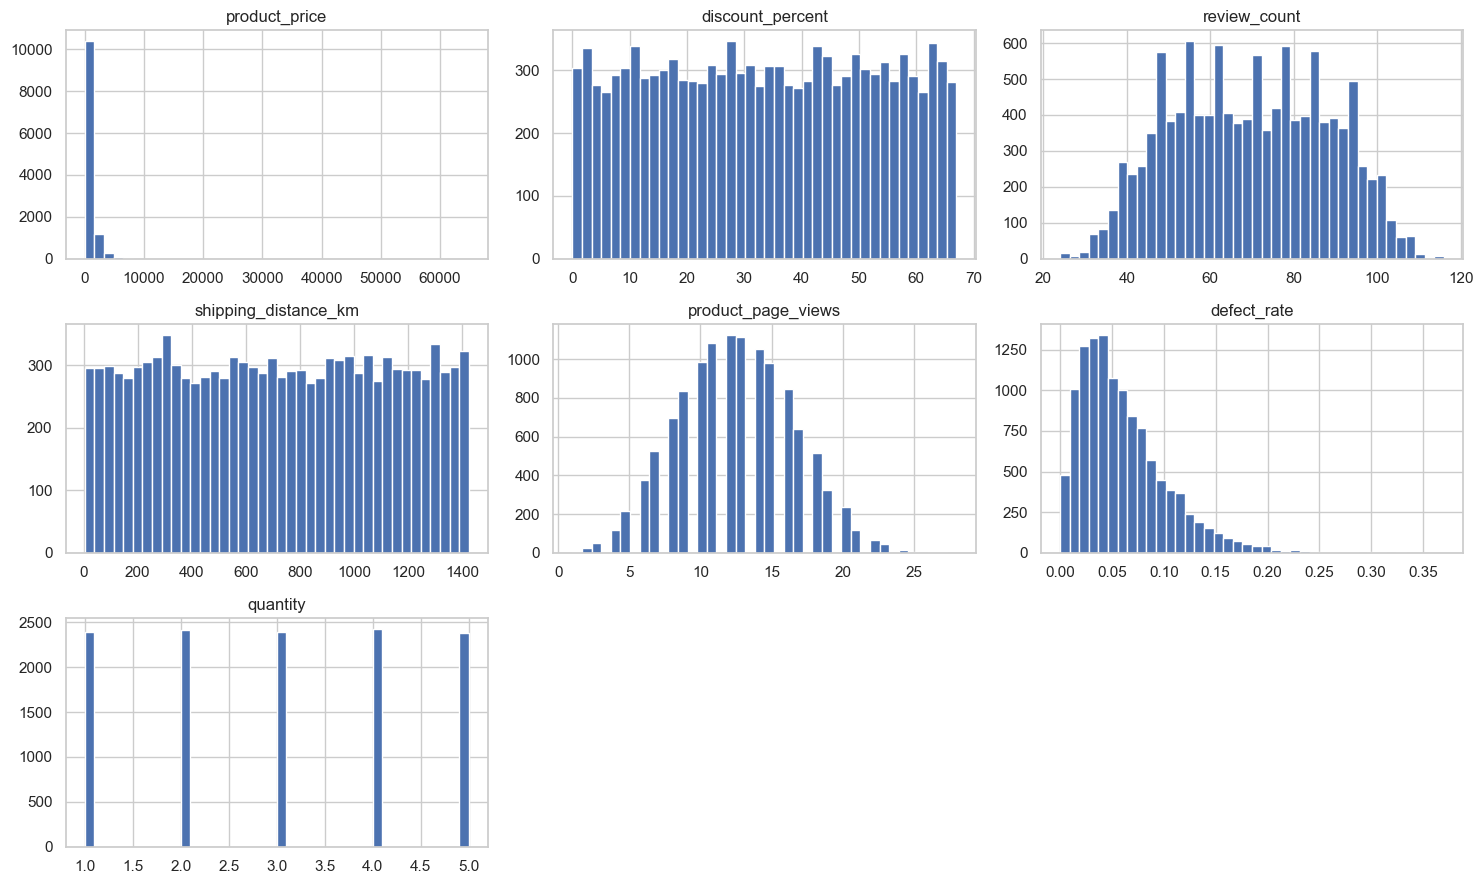

In [17]:
##further stats in the form of histogram

num_show= ["product_price", "discount_percent", "review_count", "shipping_distance_km", "product_page_views", "defect_rate", "quantity"]   #storing in a variable later acess through df[]

df[num_show].hist(figsize=(15, 9), bins= 40)
plt.tight_layout()
plt.show()

In [18]:
df["product_price"].value_counts().sort_index(ascending=False)

product_price
64878.67    1
54530.30    1
51785.32    1
46335.19    1
38309.37    1
           ..
24.60       1
23.98       1
23.62       1
19.83       1
19.51       1
Name: count, Length: 11573, dtype: int64

### Correlation with Target
Bacially we are taking all numerical columns and comparing them with Target variable, like if they changes how much target variable is changing

In [19]:
corr= df.select_dtypes(include=[np.number]).corr()
corr

,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
product_price,1.000000,-0.016544,-0.009996,0.011318,0.004471,-0.005059,-0.004302,-0.006108,-0.003224,-0.020734,0.008962,0.005713,0.000894,0.002893,0.012480,-0.004764,-0.005788,-0.005461,0.002545,-0.003023
discount_percent,-0.016544,1.000000,0.000143,-0.001287,0.007751,-0.014156,-0.003496,0.018814,0.001693,0.005724,-0.006852,-0.011614,-0.000393,-0.004087,0.005830,-0.005076,-0.000921,0.016842,0.001497,0.009022
product_rating,-0.009996,0.000143,1.000000,-0.004054,-0.009272,-0.013554,-0.006133,0.002965,-0.003017,0.001398,-0.008732,0.007746,-0.009657,-0.000152,0.000457,0.015325,0.016439,0.001983,-0.002238,-0.110463
review_count,0.011318,-0.001287,-0.004054,1.000000,0.004870,0.014399,0.009583,-0.000850,0.009161,0.001629,0.004011,0.002190,-0.006908,0.000360,0.008228,-0.009608,-0.002893,-0.003473,0.006936,0.005825
fragile_item,0.004471,0.007751,-0.009272,0.004870,1.000000,0.018553,-0.005197,0.003906,-0.011399,0.000653,-0.010058,0.004545,-0.008517,0.013720,0.009213,-0.000359,0.000184,-0.002178,0.000701,0.258118
warranty_available,-0.005059,-0.014156,-0.013554,0.014399,0.018553,1.000000,0.014906,-0.004160,0.017477,0.005117,0.008828,-0.005481,-0.005895,-0.005424,-0.013420,0.014134,0.015358,0.011117,-0.000900,-0.213782
product_return_rate,-0.004302,-0.003496,-0.006133,0.009583,-0.005197,0.014906,1.000000,0.004466,0.828173,0.002362,0.012690,0.007550,-0.009250,0.000396,-0.001079,-0.009231,0.012313,0.000120,-0.007042,0.312953
category_return_rate,-0.006108,0.018814,0.002965,-0.000850,0.003906,-0.004160,0.004466,1.000000,0.003246,-0.005091,0.006205,0.015878,-0.007067,-0.016087,-0.014060,0.000243,0.005410,-0.005486,-0.004417,-0.006420
brand_return_rate,-0.003224,0.001693,-0.003017,0.009161,-0.011399,0.017477,0.828173,0.003246,1.000000,-0.010206,0.008259,0.001791,-0.012656,-0.006052,-0.004020,-0.010581,0.008980,0.001996,-0.014422,0.336750
defect_rate,-0.020734,0.005724,0.001398,0.001629,0.000653,0.005117,0.002362,-0.005091,-0.010206,1.000000,-0.000128,0.001354,0.000302,0.014904,0.002763,-0.005108,-0.005438,-0.004293,-0.002231,0.073658


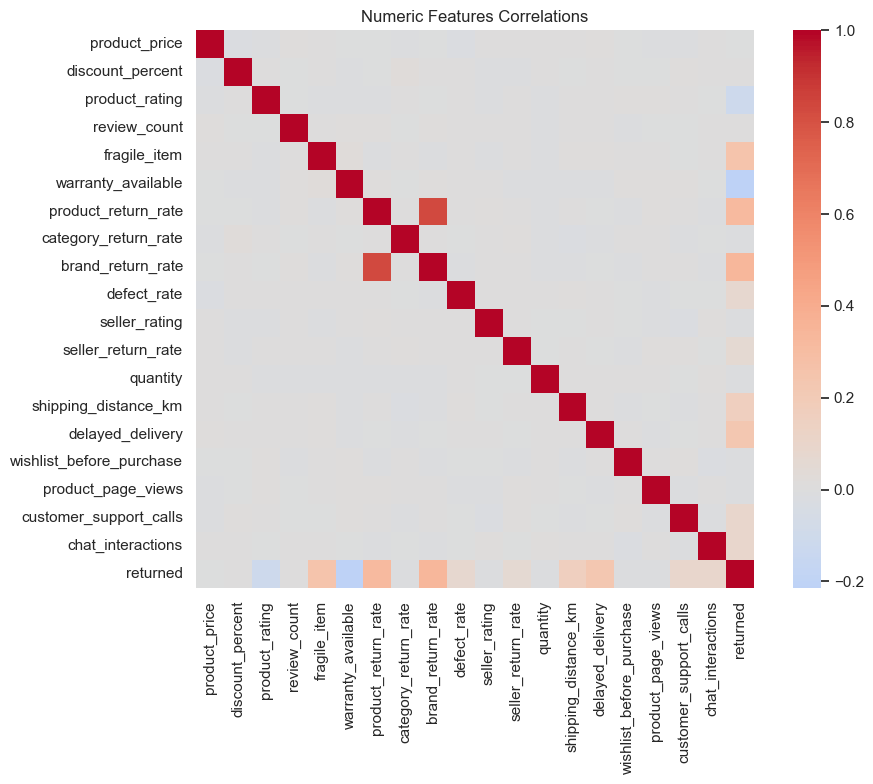

brand_return_rate           0.337
product_return_rate         0.313
fragile_item                0.258
delayed_delivery            0.229
warranty_available         -0.214
shipping_distance_km        0.162
product_rating             -0.110
customer_support_calls      0.094
chat_interactions           0.092
defect_rate                 0.074
seller_return_rate          0.059
product_page_views         -0.014
quantity                   -0.013
seller_rating              -0.010
discount_percent            0.009
wishlist_before_purchase   -0.009
category_return_rate       -0.006
review_count                0.006
product_price              -0.003
Name: returned, dtype: float64


In [20]:
#ploting the Heat Map

plt.figure(figsize=(10, 8))

# Select numerical columns and calculate correlation
corr = df.select_dtypes(include=[np.number]).corr()

# Plot correlation heatmap
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    square=True,
    
    fmt=".2f"
)

plt.title("Numeric Features Correlations")
plt.tight_layout()
plt.show()


# Correlation of every feature with returned
target_corr = corr["returned"].drop("returned")

target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
).round(3)

print(target_corr)

#### Data cleaning

In [21]:
#we have column names that are same 
df["fulfillment_type"].value_counts()

fulfillment_type
Marketplace Fulfilled     7193
Seller Fulfilled          4747
marketplace fulfilled       60
Name: count, dtype: int64

In [22]:
#and storing in new dataframe 
df_clean= df.copy()   #--> by default it is shallow copy
df_clean

,order_id,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,ORD100000,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,0.172,0.173,0.219,0.116,4.1,0.128,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,ORD100001,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,0.168,0.125,0.155,0.031,4.2,0.171,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,ORD100002,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,0.045,0.125,0.103,0.057,4.1,0.186,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0
3,ORD100003,Electronics,Laptops,Brand_30,1301.55,25.3,3.8,57.0,0,1,0.066,0.119,0.085,0.064,3.9,0.133,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,0
4,ORD100004,Electronics,Laptops,Brand_15,1402.90,30.6,3.0,71.0,0,1,0.183,0.075,0.177,0.076,4.6,0.172,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,ORD111995,Home,Furniture,Brand_18,246.32,50.8,4.4,81.0,1,0,0.095,0.197,0.089,0.046,2.9,0.200,Marketplace Fulfilled,COD,5,393.3,0,0,10,0,2,1
11996,ORD111996,Books,Academic,Brand_20,218.97,10.3,3.4,47.0,0,1,0.133,0.114,0.148,0.048,3.9,0.028,Marketplace Fulfilled,Credit Card,2,96.8,0,1,7,1,0,0
11997,ORD111997,Electronics,Laptops,Brand_13,1463.52,32.6,4.3,77.0,1,0,0.184,0.006,0.132,0.044,3.2,0.187,Marketplace Fulfilled,Credit Card,3,1218.5,0,1,14,1,0,0
11998,ORD111998,Electronics,Mobiles,Brand_5,96.32,13.1,4.1,91.0,1,1,0.048,0.082,0.010,0.023,3.2,0.125,Seller Fulfilled,Credit Card,3,337.3,0,0,7,0,0,0


In [23]:
#for this we are going to change filfillment column
df_clean["fulfillment_type"]= df_clean["fulfillment_type"].astype("string").str.strip().str.title()  #1. convert it into string, then strip for extra spaces, then make capital word for every starting word
df_clean["fulfillment_type"].value_counts()    #it will merge into 1 as you can see below

fulfillment_type
Marketplace Fulfilled    7253
Seller Fulfilled         4747
Name: count, dtype: Int64

In [24]:
#we don't need order_id column so we are going to drop that

df_clean= df_clean.drop(columns= ['order_id'])
df_clean.head(2)

,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,Beauty,Haircare,Brand_23,844.1,65.2,2.1,96.0,1,1,0.172,0.173,0.219,0.116,4.1,0.128,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,Toys,Educational,Brand_9,559.9,30.1,4.1,87.0,0,1,0.168,0.125,0.155,0.031,4.2,0.171,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0


In [25]:
#droping duplicates 
before= len(df_clean)
df_clean= df_clean.drop_duplicates().reset_index(drop= True)
print(f"\n Dropped {before-len(df_clean)} duplicates_shape: {df_clean.shape}")


 Dropped 0 duplicates_shape: (12000, 25)


In [26]:
df.columns

Index(['order_id', 'product_category', 'sub_category', 'brand',
       'product_price', 'discount_percent', 'product_rating', 'review_count',
       'fragile_item', 'warranty_available', 'product_return_rate',
       'category_return_rate', 'brand_return_rate', 'defect_rate',
       'seller_rating', 'seller_return_rate', 'fulfillment_type',
       'payment_method', 'quantity', 'shipping_distance_km',
       'delayed_delivery', 'wishlist_before_purchase', 'product_page_views',
       'customer_support_calls', 'chat_interactions', 'returned'],
      dtype='object')

#### Feature Engineering

In [27]:
#we have to transform product_price column by using log transformation (because it is right skewed) and concatenate two columns and drop one
#instead of writing all seperate we are going to write a function for this
def add_features(d):
    d["total_support_contacts"]= d["customer_support_calls"] + d["chat_interactions"]
    d["log_prices"]= np.log1p(d["product_price"])
    d= d.drop(columns= ["product_price", "customer_support_calls", "chat_interactions"])
    return d

df_feat= add_features(df_clean)
df_feat.head(5)

,product_category,sub_category,brand,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,returned,total_support_contacts,log_prices
0,Beauty,Haircare,Brand_23,65.2,2.1,96.0,1,1,0.172,0.173,0.219,0.116,4.1,0.128,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,1,0,6.739455
1,Toys,Educational,Brand_9,30.1,4.1,87.0,0,1,0.168,0.125,0.155,0.031,4.2,0.171,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,6.329543
2,Electronics,Laptops,Brand_21,53.4,3.0,75.0,0,0,0.045,0.125,0.103,0.057,4.1,0.186,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,7.367033
3,Electronics,Laptops,Brand_30,25.3,3.8,57.0,0,1,0.066,0.119,0.085,0.064,3.9,0.133,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,7.172079
4,Electronics,Laptops,Brand_15,30.6,3.0,71.0,0,1,0.183,0.075,0.177,0.076,4.6,0.172,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,7.247009


<Axes: >

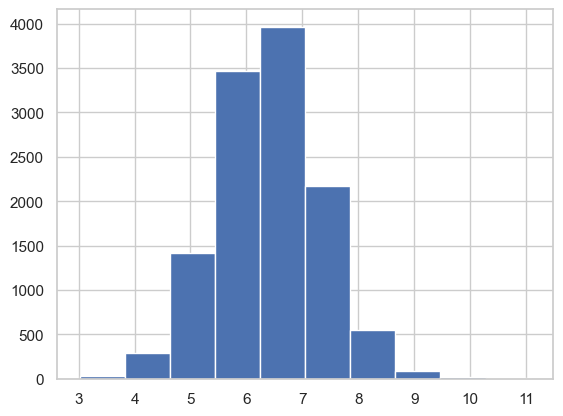

In [28]:
#now we can look log_prices, it gonna look more uniform
df_feat["log_prices"].hist()

In [29]:
#saving it into new csv file
df_feat.to_csv("dataset/cleaned_returns.csv", index= False)

In [30]:
new_cols= ["total_support_contacts", "log_prices"]
df_feat[new_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
total_support_contacts,12000.0,0.793000,0.888285,0.000000,0.000000,1.000000,1.000000,6.00000
log_prices,12000.0,6.407976,0.922538,3.020913,5.796772,6.394376,7.008862,11.08029


In [31]:
df_feat.columns          # Display all column names

df_feat.shape            # (number of rows, number of columns)

df_feat.columns.tolist() # Convert column names into a list

['product_category',
 'sub_category',
 'brand',
 'discount_percent',
 'product_rating',
 'review_count',
 'fragile_item',
 'warranty_available',
 'product_return_rate',
 'category_return_rate',
 'brand_return_rate',
 'defect_rate',
 'seller_rating',
 'seller_return_rate',
 'fulfillment_type',
 'payment_method',
 'quantity',
 'shipping_distance_km',
 'delayed_delivery',
 'wishlist_before_purchase',
 'product_page_views',
 'returned',
 'total_support_contacts',
 'log_prices']

### Training the model

In [32]:
from sklearn.model_selection import train_test_split


In [33]:
X= df_feat.drop(columns= ["returned"])
y= df_feat["returned"].astype(int)

X_train, X_test, y_train, y_test= train_test_split(
    X, 
    y,
    test_size=0.20, 
    stratify=y, 
    random_state=42, 
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (9600, 23) Test: (2400, 23)


In [34]:
df_feat.columns.tolist()

['product_category',
 'sub_category',
 'brand',
 'discount_percent',
 'product_rating',
 'review_count',
 'fragile_item',
 'warranty_available',
 'product_return_rate',
 'category_return_rate',
 'brand_return_rate',
 'defect_rate',
 'seller_rating',
 'seller_return_rate',
 'fulfillment_type',
 'payment_method',
 'quantity',
 'shipping_distance_km',
 'delayed_delivery',
 'wishlist_before_purchase',
 'product_page_views',
 'returned',
 'total_support_contacts',
 'log_prices']

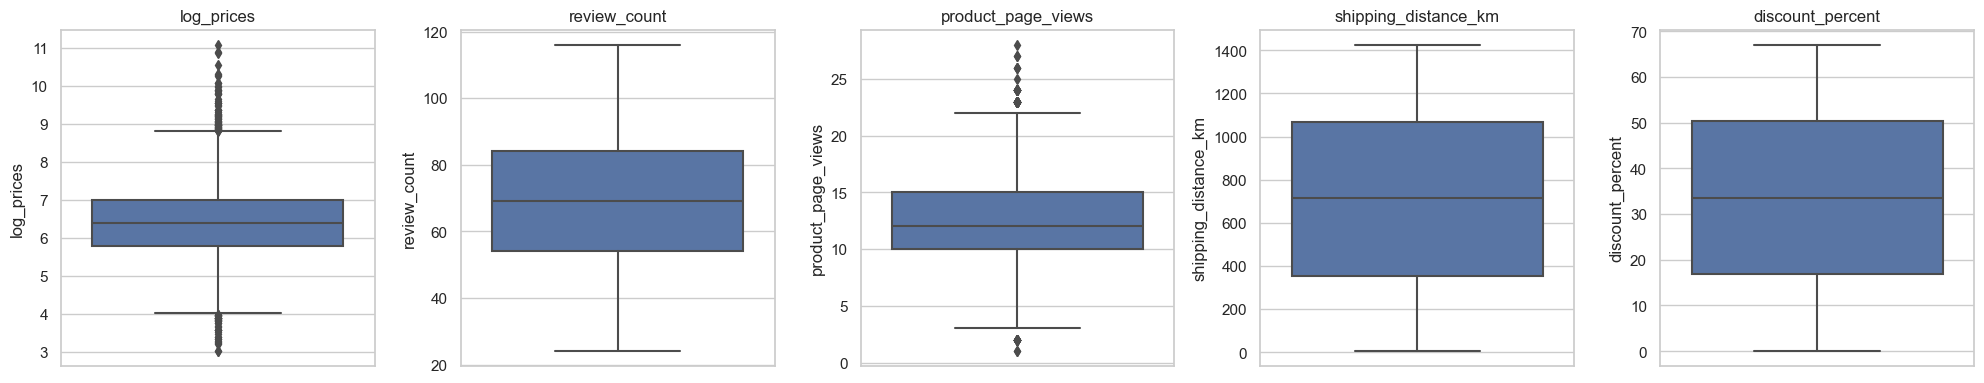

In [35]:
#using box plot to see outliers

#defining which columns we need
box_col= ["log_prices", "review_count", "product_page_views", "shipping_distance_km", "discount_percent"]

fig, axes= plt.subplots(1, len(box_col), figsize= (20, 4))

for ax, c in zip(axes, box_col):
    sns.boxplot(y= X_train[c], ax= ax, color= "#4c72b0")
    ax.set_title(c)

plt.tight_layout()
plt.show()

#### outlier removal

In [36]:
# Remove extreme outliers (Q3 + 3*IQR) on log_price - training set only.
# NOTE: with product_price already log-transformed, the tail is tamed, so this now removes
# very few rows. review_count / product_page_views are near-symmetric and bounded, so IQR
# outlier removal on them is not warranted (it would just clip legitimate values). We keep
# the step on log_price alone as a light, defensible guard against any residual extremes.

In [37]:

outlier_cols = ["log_prices"]    #Select the column
#Create a Boolean mask -A mask is a collection of True and False values used to filter rows.
mask = pd.Series(True, index=X_train.index)
for c in outlier_cols:
    q1, q3 = X_train[c].quantile(0.25), X_train[c].quantile(0.75)
    upper = q3 + 3 * (q3 - q1)
    mask &= X_train[c] <= upper
removed = (~mask).sum()
X_train, y_train = X_train[mask], y_train[mask]
print(f"Removed {removed} extreme-outlier rows from training set. New train shape: {X_train.shape}")

Removed 3 extreme-outlier rows from training set. New train shape: (9597, 23)


In [38]:
df_feat.columns.tolist()

['product_category',
 'sub_category',
 'brand',
 'discount_percent',
 'product_rating',
 'review_count',
 'fragile_item',
 'warranty_available',
 'product_return_rate',
 'category_return_rate',
 'brand_return_rate',
 'defect_rate',
 'seller_rating',
 'seller_return_rate',
 'fulfillment_type',
 'payment_method',
 'quantity',
 'shipping_distance_km',
 'delayed_delivery',
 'wishlist_before_purchase',
 'product_page_views',
 'returned',
 'total_support_contacts',
 'log_prices']

In [39]:
# Identify feature groups
binary_flags = ["fragile_item", "warranty_available", "delayed_delivery", "wishlist_before_purchase"]
categorical_features = ["product_category", "sub_category", "brand", "fulfillment_type", "payment_method"]
numeric_features = [c for c in X_train.columns if c not in binary_flags + categorical_features]

all_features = numeric_features + binary_flags  # continuous + binary

print(f"Numeric features ({len(numeric_features)}):", numeric_features)
print(f"Binary flags ({len(binary_flags)}):", binary_flags)
print(f"Categorical features ({len(categorical_features)}):", categorical_features)

Numeric features (14): ['discount_percent', 'product_rating', 'review_count', 'product_return_rate', 'category_return_rate', 'brand_return_rate', 'defect_rate', 'seller_rating', 'seller_return_rate', 'quantity', 'shipping_distance_km', 'product_page_views', 'total_support_contacts', 'log_prices']
Binary flags (4): ['fragile_item', 'warranty_available', 'delayed_delivery', 'wishlist_before_purchase']
Categorical features (5): ['product_category', 'sub_category', 'brand', 'fulfillment_type', 'payment_method']


In [40]:
#substitue NA values 
X_train.isnull().sum()

product_category              0
sub_category                  0
brand                         0
discount_percent              0
product_rating              199
review_count                 97
fragile_item                  0
warranty_available            0
product_return_rate           0
category_return_rate          0
brand_return_rate             0
defect_rate                   0
seller_rating               150
seller_return_rate            0
fulfillment_type              0
payment_method                0
quantity                      0
shipping_distance_km         90
delayed_delivery              0
wishlist_before_purchase      0
product_page_views            0
total_support_contacts        0
log_prices                    0
dtype: int64

In [41]:
#impute missing values (median for training set)
train_median= X_train[all_features].median().to_dict()
train_median

{'discount_percent': 33.5,
 'product_rating': 3.9,
 'review_count': 69.0,
 'product_return_rate': 0.134,
 'category_return_rate': 0.12,
 'brand_return_rate': 0.136,
 'defect_rate': 0.051,
 'seller_rating': 4.1,
 'seller_return_rate': 0.121,
 'quantity': 3.0,
 'shipping_distance_km': 714.1,
 'product_page_views': 12.0,
 'total_support_contacts': 1.0,
 'log_prices': 6.389636457722005,
 'fragile_item': 0.0,
 'warranty_available': 0.0,
 'delayed_delivery': 0.0,
 'wishlist_before_purchase': 0.0}

In [42]:
#fill those values with null values (train_median)
X_train[all_features]= X_train[all_features].fillna(train_median)
X_test[all_features]= X_test[all_features].fillna(train_median)

X_train.isnull().sum()

product_category            0
sub_category                0
brand                       0
discount_percent            0
product_rating              0
review_count                0
fragile_item                0
warranty_available          0
product_return_rate         0
category_return_rate        0
brand_return_rate           0
defect_rate                 0
seller_rating               0
seller_return_rate          0
fulfillment_type            0
payment_method              0
quantity                    0
shipping_distance_km        0
delayed_delivery            0
wishlist_before_purchase    0
product_page_views          0
total_support_contacts      0
log_prices                  0
dtype: int64

In [43]:
#scaling numeric features (standardscaler())
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()

X_train[numeric_features]= scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.fit_transform(X_test[numeric_features])

X_train.head(3)

,product_category,sub_category,brand,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,total_support_contacts,log_prices
6601,Fashion,Accessories,Brand_23,-0.290112,0.504033,-0.886840,0,1,1.304073,0.700800,1.472492,-0.003152,0.014598,1.013094,Marketplace Fulfilled,Wallet,1.413045,0.473585,0,1,0.122844,-0.892091,-0.734596
9297,Fashion,Accessories,Brand_18,-1.028937,-1.560569,-1.920866,0,0,-0.885986,-0.635710,-0.339220,-1.040534,-2.359959,-2.055507,Marketplace Fulfilled,Wallet,-0.003839,-0.604359,0,0,0.373894,-0.892091,-0.423596
6057,Fashion,Accessories,Brand_22,-0.894605,0.504033,-1.213375,0,1,-1.887974,-0.007955,-1.446377,-0.899073,0.878073,0.721663,Marketplace Fulfilled,UPI,-1.420723,-1.458934,0,1,0.373894,-0.892091,0.107722


In [44]:
#now for one-hot encoding for categorical features
X_train= pd.get_dummies(X_train, columns= categorical_features, dtype=int)
X_test= pd.get_dummies(X_test, columns= categorical_features, dtype=int)

X_train.head(3)

,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,total_support_contacts,log_prices,product_category_Beauty,product_category_Books,product_category_Electronics,product_category_Fashion,product_category_Home,product_category_Sports,product_category_Toys,sub_category_Academic,sub_category_Accessories,sub_category_Action Figures,sub_category_Audio,sub_category_Decor,sub_category_Educational,sub_category_Fiction,sub_category_Fitness,sub_category_Footwear,sub_category_Furniture,sub_category_Haircare,sub_category_Kids,sub_category_Kitchen,sub_category_Laptops,sub_category_Makeup,sub_category_Men,sub_category_Mobiles,sub_category_Non-Fiction,sub_category_Outdoor,sub_category_Outdoor Play,sub_category_Skincare,sub_category_Team Sports,sub_category_Women,brand_Brand_1,brand_Brand_10,brand_Brand_11,brand_Brand_12,brand_Brand_13,brand_Brand_14,brand_Brand_15,brand_Brand_16,brand_Brand_17,brand_Brand_18,brand_Brand_19,brand_Brand_2,brand_Brand_20,brand_Brand_21,brand_Brand_22,brand_Brand_23,brand_Brand_24,brand_Brand_25,brand_Brand_26,brand_Brand_27,brand_Brand_28,brand_Brand_29,brand_Brand_3,brand_Brand_30,brand_Brand_4,brand_Brand_5,brand_Brand_6,brand_Brand_7,brand_Brand_8,brand_Brand_9,fulfillment_type_Marketplace Fulfilled,fulfillment_type_Seller Fulfilled,payment_method_COD,payment_method_Credit Card,payment_method_Debit Card,payment_method_UPI,payment_method_Wallet
6601,-0.290112,0.504033,-0.886840,0,1,1.304073,0.700800,1.472492,-0.003152,0.014598,1.013094,1.413045,0.473585,0,1,0.122844,-0.892091,-0.734596,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
9297,-1.028937,-1.560569,-1.920866,0,0,-0.885986,-0.635710,-0.339220,-1.040534,-2.359959,-2.055507,-0.003839,-0.604359,0,0,0.373894,-0.892091,-0.423596,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
6057,-0.894605,0.504033,-1.213375,0,1,-1.887974,-0.007955,-1.446377,-0.899073,0.878073,0.721663,-1.420723,-1.458934,0,1,0.373894,-0.892091,0.107722,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0


In [45]:
#Align columns (test may have missing /extra categories)
#We're doing this to ensure the training and testing datasets have exactly the same columns, in exactly the same order.
X_test= X_test.reindex(columns= X_train.columns, fill_value=0)

model_columns= list(X_train.columns)
print(f"Final Features count: {len(model_columns)}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Final Features count: 85
Train: (9597, 85), Test: (2400, 85)


#### Training multiple models to see which model gives us best performance then choose that model

In [46]:
# Calculate scale_pos_weight for XGBoost
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
spw = neg_count / pos_count

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=5,
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=spw,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
}

fitted = {}
for name, est in models.items():
    est.fit(X_train, y_train)
    fitted[name] = est
    print("Trained:", name)

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: XGBoost


#### Compare model performance

In [47]:
def evaluate(model, X, y):
    pred = model.predict(X)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
    }

comparison = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in fitted.items()}).T
comparison = comparison.sort_values("F1", ascending=False)
comparison.round(4)

,Accuracy,Precision,Recall,F1
Logistic Regression,0.8533,0.7125,0.8669,0.7822
XGBoost,0.8462,0.7123,0.8285,0.7660
Random Forest,0.8454,0.8266,0.6214,0.7095
Decision Tree,0.7875,0.6439,0.6722,0.6577


#### comparison plot

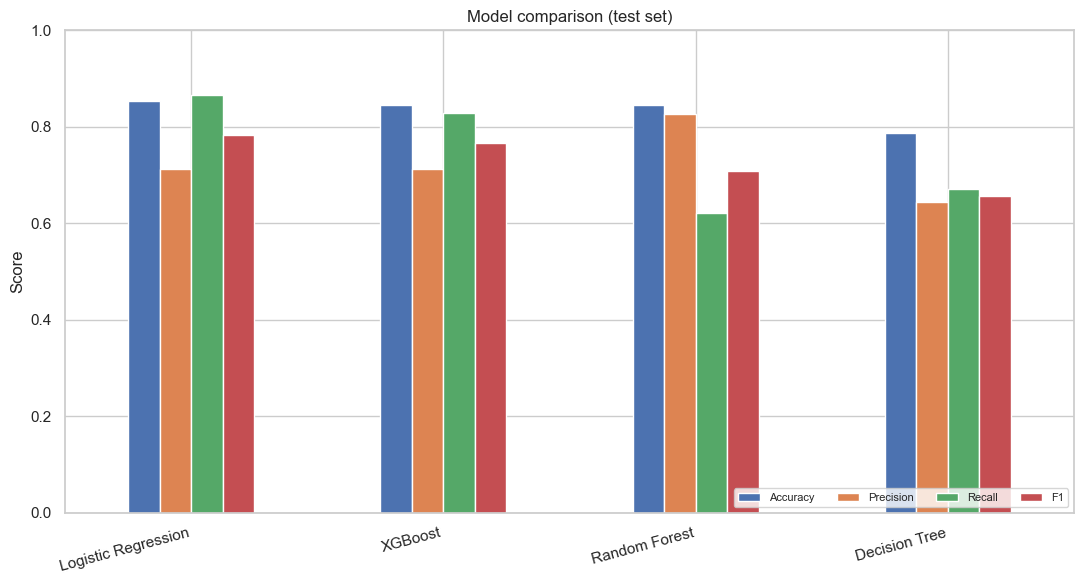

In [48]:
comparison.plot(kind="bar", figsize=(11, 6))
plt.title("Model comparison (test set)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right", ncol=4, fontsize=8)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Why Precision and Recall matter more than Accuracy

When classes are uneven, a model that always predicts the majority class scores high
accuracy while catching none of the minority class. **Recall** captures value (each missed
return costs the full reverse-logistics + refund); **Precision** controls the cost of
wasted preventive actions. The business favours higher recall; **F1**/**ROC-AUC** summarise
the balance.

In [49]:
#selecting best model
best_name = comparison.index[0]
print("Best model by F1:", best_name, "| imbalance: class_weight='balanced'")

Best model by F1: Logistic Regression | imbalance: class_weight='balanced'


In [50]:
#This code selects our best-performing model, evaluates it again on the test dataset, and prints its evaluation metrics in a readable format.
final_model = fitted[best_name]
tuned_metrics = evaluate(final_model, X_test, y_test)
print(f"Final {best_name} (class_weight='balanced') test metrics:")
for k, v in tuned_metrics.items():
    print(f"  {k:10s}: {v:.4f}")

Final Logistic Regression (class_weight='balanced') test metrics:
  Accuracy  : 0.8533
  Precision : 0.7125
  Recall    : 0.8669
  F1        : 0.7822


### Confusion Matrix and Classification Report.

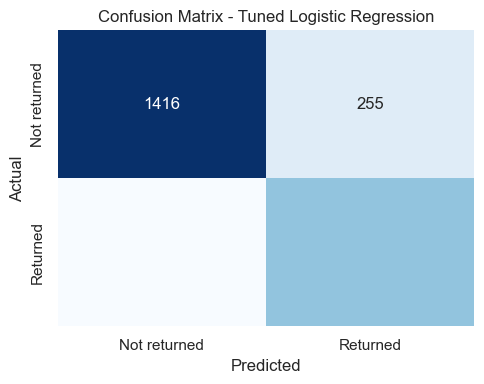

              precision    recall  f1-score   support

Not returned     0.9359    0.8474    0.8894      1671
    Returned     0.7125    0.8669    0.7822       729

    accuracy                         0.8533      2400
   macro avg     0.8242    0.8572    0.8358      2400
weighted avg     0.8680    0.8533    0.8569      2400



In [51]:
cm = confusion_matrix(y_test, final_model.predict(X_test))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Not returned", "Returned"], yticklabels=["Not returned", "Returned"])
plt.title(f"Confusion Matrix - Tuned {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

#classification report
print(classification_report(y_test, final_model.predict(X_test),
                            target_names=["Not returned", "Returned"], digits=4))

In [52]:
final_model.coef_

array([[ 7.49640642e-03, -5.23688306e-01,  2.66414372e-03,
         2.87315448e+00, -2.16213770e+00,  4.22347820e-01,
        -1.02498223e-02,  3.61568424e-01,  3.46431407e-01,
        -2.82921794e-02,  2.72283883e-01, -2.00526907e-02,
         7.45498793e-01,  2.56651900e+00, -3.55757208e-02,
        -3.59017370e-02,  6.69271273e-01,  2.87886855e-03,
        -1.63817860e-02,  1.64707093e-02, -1.11914650e-02,
        -3.66928832e-02,  1.08690232e-01, -1.12832297e-01,
         4.74574613e-02,  9.83903695e-02,  1.15313048e-01,
        -2.74706724e-01, -8.78850150e-02, -3.92188590e-02,
         3.25024587e-01,  1.49700518e-01, -2.21727283e-02,
         4.99925695e-02,  2.25951864e-01, -1.42505232e-01,
        -5.83904625e-02, -7.80427735e-02, -1.20801531e-01,
         1.21305595e-01, -2.16121685e-01,  1.97495081e-01,
        -2.31620178e-01, -1.06771175e-01, -2.86040138e-03,
         4.81785074e-03,  1.61116061e-02,  7.25136473e-02,
         3.61613575e-01, -1.34210484e+00,  1.44744712e+0

In [53]:
final_model.intercept_

array([-1.45283219])

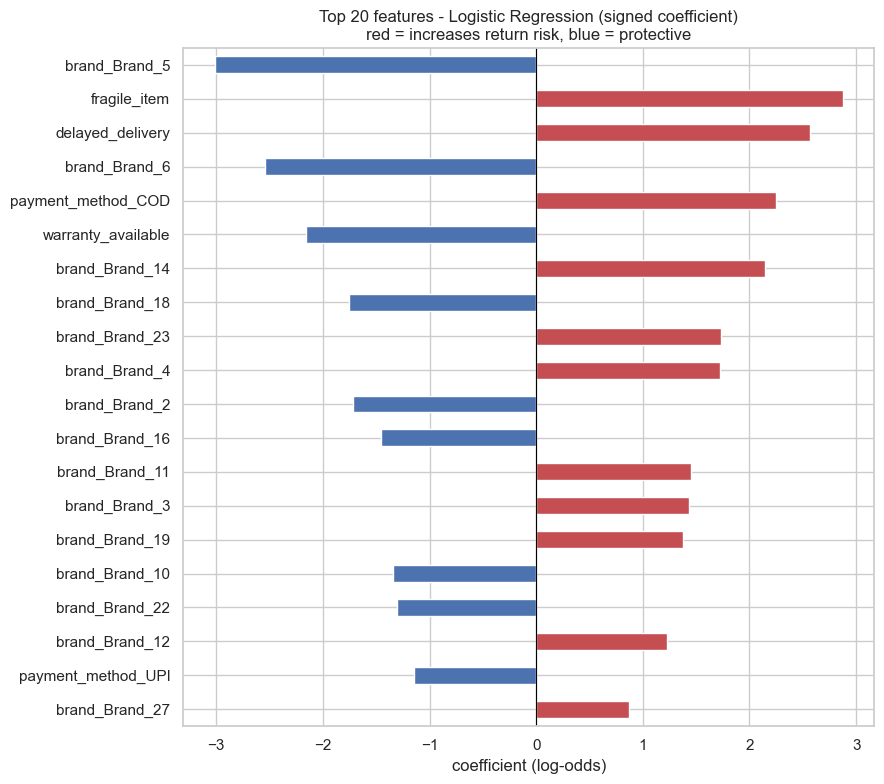

brand_Brand_5        -3.0133
fragile_item          2.8732
delayed_delivery      2.5665
brand_Brand_6        -2.5407
payment_method_COD    2.2520
warranty_available   -2.1621
brand_Brand_14        2.1411
brand_Brand_18       -1.7573
brand_Brand_23        1.7293
brand_Brand_4         1.7220
brand_Brand_2        -1.7180
brand_Brand_16       -1.4552
brand_Brand_11        1.4474
brand_Brand_3         1.4369
brand_Brand_19        1.3748
brand_Brand_10       -1.3421
brand_Brand_22       -1.3093
brand_Brand_12        1.2266
payment_method_UPI   -1.1462
brand_Brand_27        0.8697
dtype: float64

In [54]:
# Rank features by coefficient MAGNITUDE (so the strongest predictors are shown), but keep
# the SIGN via colour: red = pushes toward a return, blue = protective (pushes away).
# This is better than plotting raw signed values and taking head(20), which would silently
# drop the strongest features when their coefficient is negative.

imp = pd.Series(final_model.coef_[0], index=model_columns)
top = imp.reindex(imp.abs().sort_values(ascending=False).index).head(20)
colors = ["#c44e52" if v > 0 else "#4c72b0" for v in top]

plt.figure(figsize=(9, 8))
top[::-1].plot(kind="barh", color=colors[::-1])
plt.axvline(0, color="black", lw=0.8)
plt.title(f"Top 20 features - {best_name} (signed coefficient)\nred = increases return risk, blue = protective")
plt.xlabel("coefficient (log-odds)")
plt.tight_layout(); plt.show()
top.round(4)

## Save the final model using joblib

We save the trained model along with the scaler, feature lists, and metadata needed for
inference. The saved bundle contains everything needed to preprocess a raw order and predict.

In [55]:
# Feature importance dict for the API
fi_values = np.abs(final_model.coef_[0])
fi_series = pd.Series(fi_values, index=model_columns).sort_values(ascending=False)
feature_importance = [{"feature": k, "importance": round(float(v), 6)}
                      for k, v in fi_series.head(20).items()]

model_data = {
    "model": final_model,
    "model_name": best_name,
    "scaler": scaler,
    "model_columns": model_columns,
    "numeric_features": numeric_features,
    "binary_flags": binary_flags,
    "categorical_features": categorical_features,
    "train_median": train_median,
    "metrics": tuned_metrics,
    "feature_importance": feature_importance,
    "threshold": 0.5,
}




In [56]:
import joblib

In [58]:
feature_importance = [{"feature": k, "importance": round(float(v), 6)}
                      for k, v in fi_series.head(20).items()]
feature_importance

[{'feature': 'brand_Brand_5', 'importance': 3.013261},
 {'feature': 'fragile_item', 'importance': 2.873154},
 {'feature': 'delayed_delivery', 'importance': 2.566519},
 {'feature': 'brand_Brand_6', 'importance': 2.540687},
 {'feature': 'payment_method_COD', 'importance': 2.252017},
 {'feature': 'warranty_available', 'importance': 2.162138},
 {'feature': 'brand_Brand_14', 'importance': 2.141099},
 {'feature': 'brand_Brand_18', 'importance': 1.757293},
 {'feature': 'brand_Brand_23', 'importance': 1.729348},
 {'feature': 'brand_Brand_4', 'importance': 1.722003},
 {'feature': 'brand_Brand_2', 'importance': 1.717988},
 {'feature': 'brand_Brand_16', 'importance': 1.455246},
 {'feature': 'brand_Brand_11', 'importance': 1.447447},
 {'feature': 'brand_Brand_3', 'importance': 1.436884},
 {'feature': 'brand_Brand_19', 'importance': 1.374773},
 {'feature': 'brand_Brand_10', 'importance': 1.342105},
 {'feature': 'brand_Brand_22', 'importance': 1.3093},
 {'feature': 'brand_Brand_12', 'importance': 1.

In [60]:
#dumping into a location using joblib later using that for FastAPI

joblib.dump(model_data, "artifacts/model_data.joblib")
print("Saved -> artifacts/model_data.joblib")

Saved -> artifacts/model_data.joblib
